# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [1]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Михальчук Антон'      # прізвище та ім'я
GROUP        = 'ШІ-32'      # шифр групи, наприклад СШІ-31
NUMBER       = 13      # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Михальчук Антон | ШІ-32 | номер 13


In [2]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 13   ·   Михальчук Антон   ·   ШІ-32

   Ринок:  Zhytomyr
   Товар:  сир кисломолочний   (у наборі даних: Curd - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [3]:
# Завдання 1. Підготовка ряду
import pandas as pd

raw = pd.read_csv('ціни_україна_2014_2017.csv')

# 1) лише свій ринок і товар
s = raw[(raw['ринок'] == MARKET) & (raw['товар'] == GOOD)].copy()
s['date'] = pd.to_datetime(dict(year=s['рік'], month=s['місяць'], day=1))
print('записів у наборі для ряду:', len(s))
print('дублікатів місяця:', s['date'].duplicated().sum())

# 2) повна місячна сітка 03.2014–12.2017 і накладання ряду на неї
grid = pd.date_range('2014-03-01', '2017-12-01', freq='MS')
series = s.set_index('date')['ціна'].reindex(grid)
series.index.name = 'date'

print('місяців у сітці:', len(grid))
print('з виміром      :', series.notna().sum())
print('порожні місяці :', [d.strftime('%Y-%m') for d in series[series.isna()].index])


записів у наборі для ряду: 45
дублікатів місяця: 0
місяців у сітці: 46
з виміром      : 45
порожні місяці : ['2017-08']


**Висновок до завдання 1:**

1. Повна місячна сітка 03.2014–12.2017 має **46** місяців, вимір ціни є для **45** із них.
2. Пропуск — **серпень 2017**.
3. За серпень 2017 у всьому наборі немає жодного запису (0, тоді як за кожен інший місяць 2017 року — по 650) — тобто зникли записи одночасно по всіх ринках і товарах. Неможливо, щоб усі ринки водночас перестали продавати, тому пропуск виник на рівні збирання чи публікації даних у джерелі (база WFP), а не через подію на житомирському ринку. У нашому ряді пропуск один; дублікатів місяців немає.


## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [4]:
# Завдання 2. Заповнення пропуску
gap = series[series.isna()].index[0]

fills = {
    'перенесення останнього (ffill)': series.ffill(),
    'лінійна інтерполяція':           series.interpolate(method='linear'),
    'кубічний сплайн':                series.interpolate(method='spline', order=3),
}

print('сусіди: липень %.2f, вересень %.2f' % (series['2017-07-01'], series['2017-09-01']))
print()
for name, filled in fills.items():
    print('%-32s %s -> %.2f' % (name, gap.strftime('%Y-%m'), filled[gap]))

# обраний спосіб — лінійна інтерполяція; далі працюємо з цим рядом
y = fills['лінійна інтерполяція']
assert y.notna().all() and len(y) == 46


сусіди: липень 71.42, вересень 73.53

перенесення останнього (ffill)   2017-08 -> 71.42
лінійна інтерполяція             2017-08 -> 72.48
кубічний сплайн                  2017-08 -> 73.86


**Висновок до завдання 2:**

1. Значення для серпня 2017 (сусіди: липень 71.42, вересень 73.53): перенесення останнього — **71.42**, лінійна інтерполяція — **72.48**, кубічний сплайн — **73.86**.
2. Обрано **лінійну інтерполяцію**. Вона спирається лише на два реальні сусідні виміри, тоді як перенесення останнього значення дивиться тільки назад, а сплайн, намагаючись зберегти плавність, створює зайві вигини: його 73.86 більше за обидва сусідні значення, тобто він «малює» пік, якого в даних немає. Лінійну інтерполяцію має й Orange (віджет Interpolate), тож значення в обох середовищах збігатиметься.
3. Заповнювати пропуск неприпустимо, коли ряд не має виміру не через втрату запису, а тому що самого спостережуваного ринку в межах джерела більше немає. У наборі це **Crimea** (дані лише за 03.2014) та **m. Sevastopol** (03–04.2014): після окупації в 2014 році ціни на цих ринках не збиралися, тож «заповнення» до 2017 року означало б вигадати понад 40 місяців даних. Наш серпень 2017 — інший випадок: ринок працював, ціна існувала, зник лише запис у джерелі, і він оточений реальними вимірами з обох боків.


## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

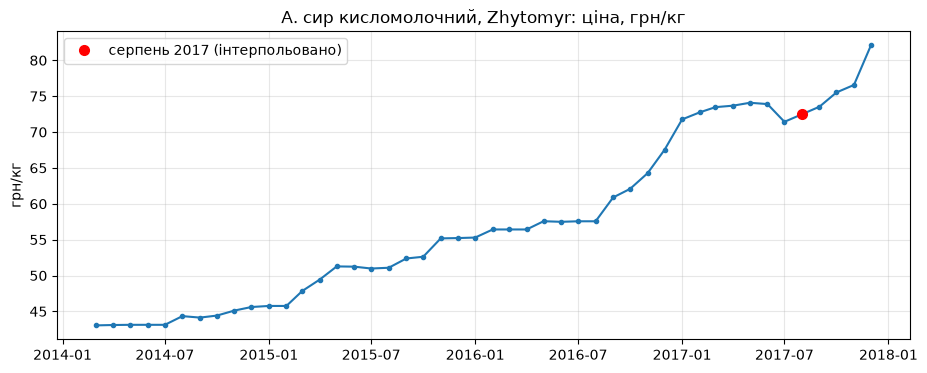

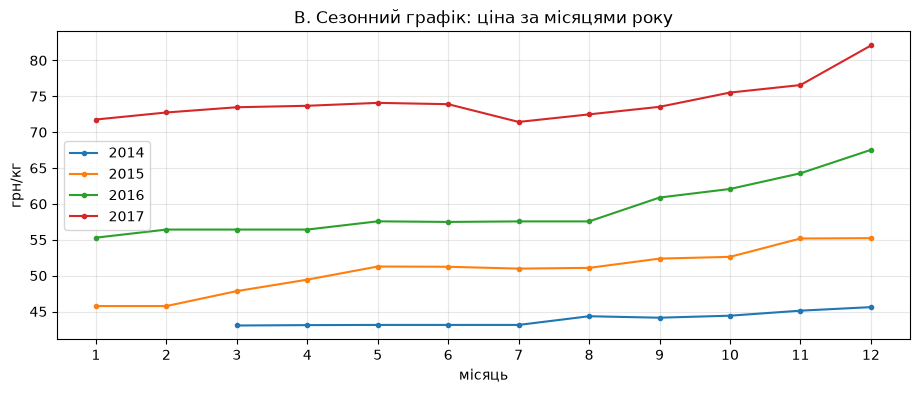

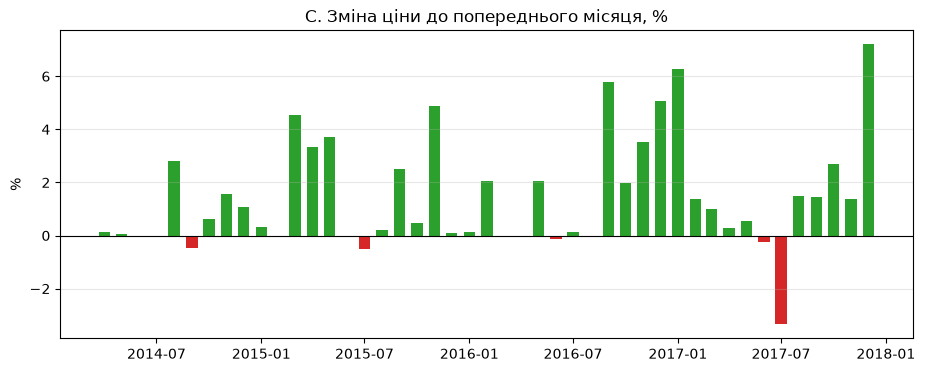

найбільші місячні зростання, %:
date
2017-12-01    7.2
2017-01-01    6.3
2016-09-01    5.8
найбільші місячні падіння, %:
date
2017-07-01   -3.3
2015-07-01   -0.5
2014-09-01   -0.5
ціна: 03.2014 = 43.05, 12.2017 = 82.08 (x1.91)


In [5]:
# Завдання 3. Візуальна розвідка
import matplotlib.pyplot as plt

# A. Лінія ціни в часі: як ціна змінювалась загалом
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(y.index, y.values, marker='o', ms=3)
ax.plot(gap, y[gap], 'o', color='red', ms=7, label='серпень 2017 (інтерпольовано)')
ax.set_title(f'A. {GOOD_UA}, {MARKET}: ціна, грн/кг')
ax.set_ylabel('грн/кг'); ax.grid(alpha=.3); ax.legend()
plt.show()

# B. Сезонний графік: кожен рік окремою лінією, по осі X — місяць
fig, ax = plt.subplots(figsize=(11, 4))
for year, part in y.groupby(y.index.year):
    ax.plot(part.index.month, part.values, marker='o', ms=3, label=str(year))
ax.set_xticks(range(1, 13))
ax.set_title('B. Сезонний графік: ціна за місяцями року')
ax.set_xlabel('місяць'); ax.set_ylabel('грн/кг'); ax.grid(alpha=.3); ax.legend()
plt.show()

# C. Місячна зміна ціни, %: наскільки великі зміни і чи є аномальні стрибки
change = y.pct_change().dropna() * 100
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(change.index, change.values, width=20,
       color=['tab:green' if v >= 0 else 'tab:red' for v in change.values])
ax.axhline(0, color='black', lw=.8)
ax.set_title('C. Зміна ціни до попереднього місяця, %')
ax.set_ylabel('%'); ax.grid(alpha=.3, axis='y')
plt.show()

print('найбільші місячні зростання, %:'); print(change.nlargest(3).round(1).to_string())
print('найбільші місячні падіння, %:');   print(change.nsmallest(3).round(1).to_string())
print('ціна: 03.2014 = %.2f, 12.2017 = %.2f (x%.2f)' % (y.iloc[0], y.iloc[-1], y.iloc[-1] / y.iloc[0]))


**Висновок до завдання 3:**

1. Питання, геометрія і шкала кожного графіка:
   * **A. Лінія ціни в часі** — *як ціна змінювалась загалом?* Лінія, бо точки впорядковані в часі й сусідні місяці пов'язані; точки-маркери показують, що вимір щомісячний, а червона точка — інтерпольований серпень 2017. Шкала лінійна і не з нуля: питання про форму руху (тренд, стрибки), а не про частку від нуля, тому вісь Y підібрана під діапазон 43–82 грн/кг. Видно: за 46 місяців ціна зросла з 43.05 до 82.08 грн/кг (×1.91), і росте вона **сходинками** — плато по кілька місяців, потім різкий стрибок.
   * **B. Сезонний графік** — *чи повторюється щороку однаковий малюнок?* По осі X місяць року, кожен рік окремою лінією: так однакові місяці різних років стоять один над одним і сезонний малюнок, якщо він є, проявився б як однакова форма ліній. Шкала та сама, що й у A. Видно: лінії років не перетинаються — різниця між роками (тренд) значно більша за коливання всередині року. Є лише слабкий натяк на просідання влітку і зростання восени–взимку, але він не повторюється чітко, тож явної сезонності графік не показує (перевіримо числом $F_S$ у завданні 4).
   * **C. Стовпці місячної зміни, %** — *наскільки великі зміни з місяця в місяць, чи є аномальні стрибки?* Стовпці, бо кожна зміна — окрема величина відносно нуля; вісь проходить через 0, колір розділяє зростання й падіння. Відсотки замість гривень, бо ціна подвоїлась і однаковий стрибок у гривнях у 2014 і 2017 роках означав би різну відносну зміну. Видно: ціна майже ніколи не падає; найбільші зростання — 12.2017 (+7.2 %), 01.2017 (+6.3 %), 09.2016 (+5.8 %).
2. **Неочікувана знахідка:** єдине помітне падіння ціни за весь ряд — **липень 2017, −3.3 %** (наступні за величиною падіння лише −0.5 %). Це не загальноукраїнський рух: по 26 ринках сиру в липні 2017 медіанна зміна +0.2 %, падіння було на 11 ринках, тоді як у липні 2015 і 2016 — на 7 і 6. Тобто в липні 2017 літнє здешевлення трапилось частіше, ніж зазвичай, але в Житомирі воно значно глибше. Причину з даних встановити не можна; можливі пояснення — локальне літнє надлишкове пропонування молока або нетиповий вимір (липень стоїть безпосередньо перед місяцем, запис за який у джерелі зник).


## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

In [6]:
# Завдання 4. Розкладання на складові

**Висновок до завдання 4:**

*(напишіть тут)*

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

In [7]:
# Завдання 5. Стаціонарність

**Висновок до завдання 5:**

*(напишіть тут)*

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [8]:
# Завдання 6. Базисні прогнози та ретроспективна перевірка

**Висновок до завдання 6:**

*(напишіть тут)*

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

In [9]:
# Завдання 7. Модель ARIMA

**Висновок до завдання 7:**

*(напишіть тут)*

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

In [10]:
# Завдання 8. Точка зміни режиму

**Висновок до завдання 8:**

*(напишіть тут)*

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [11]:
# Завдання 9. Рецензія на чужий аналіз

**Висновок до завдання 9:**

*(напишіть тут)*

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [12]:
# Завдання 10. Експорт ряду для Orange

**Висновок до завдання 10:**

*(напишіть тут)*

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

In [13]:
# Завдання 11. Потік опрацювання даних

**Висновок до завдання 11:**

*(напишіть тут)*

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

In [14]:
# Завдання 12. Автокореляція та диференціювання

**Висновок до завдання 12:**

*(напишіть тут)*

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

In [15]:
# Завдання 13. Модель і оцінювання

**Висновок до завдання 13:**

*(напишіть тут)*

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [16]:
# Завдання 14. Чому числа не збігаються

**Висновок до завдання 14:**

*(напишіть тут)*

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [17]:
# Завдання 15. Матриця напрямку зміни

**Висновок до завдання 15:**

*(напишіть тут)*

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

*(напишіть тут)*

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | |
| Для яких саме завдань | |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | |
| Що ви змінили у згенерованому результаті й чому | |
| Що з отриманого ви **перевірили самостійно** і яким способом | |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: ______________________  Дата: ______________